# Khám phá dữ liệu — Bank Marketing

> **Mục tiêu:** hiểu phân phối dữ liệu, quan sát mối liên hệ giữa đặc trưng và đăng ký tiền gửi có kỳ hạn (`y`), rồi đưa ra quyết định feature dựa trên **thời điểm dự đoán trước chiến dịch**.

**Dữ liệu:** Bank Marketing (UCI), 45.211 khách hàng, 16 đặc trưng đầu vào và nhãn `y`. Các bảng tỷ lệ bên dưới là mô tả quan sát; chúng **không chứng minh quan hệ nhân quả**. Tỷ lệ giữa nhóm cũng cần được đọc cùng quy mô mẫu.

**Cách chạy:** mở notebook từ thư mục `notebooks/` và chạy lần lượt từ trên xuống; cần có `data/raw/bank-full.csv`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.data_loader import DataLoader
from src.data_analyzer import DataAnalyzer

# Phong cách biểu đồ nhất quán, dễ đọc khi xem trên notebook/GitHub.
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "font.size": 10,
})

DATA_PATH = Path("../data/raw/bank-full.csv")
loader = DataLoader(DATA_PATH)
df = loader.load_data()

analyzer = DataAnalyzer(df)

print(f"Dataset shape: {df.shape}")

Dataset shape: (45211, 17)


## 1. Nhãn mục tiêu và mất cân bằng lớp

Bắt đầu bằng tỷ lệ `yes`/`no`. Nếu lớp đăng ký ít hơn đáng kể, accuracy đơn lẻ sẽ không đủ để đánh giá mô hình; cần theo dõi precision, recall, F1 và metric xếp hạng ở bước modeling.

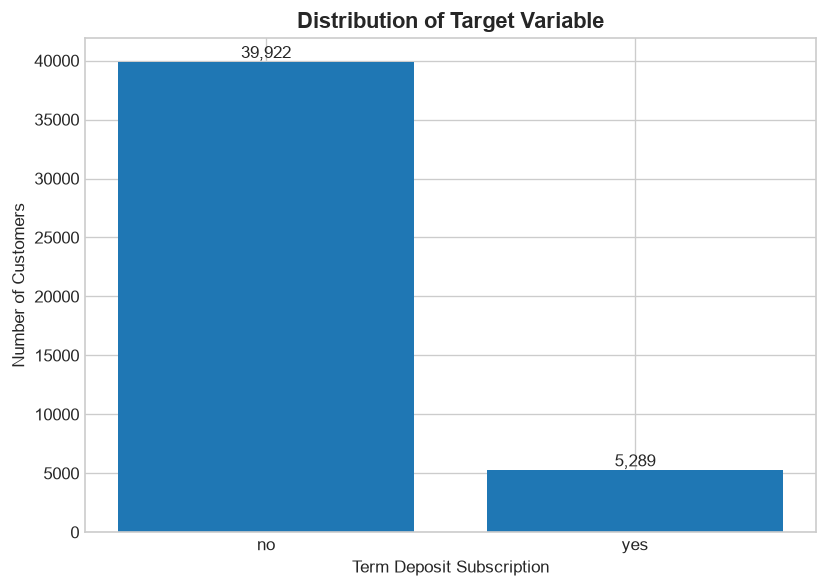

In [2]:
import matplotlib.pyplot as plt

target_counts = df["y"].value_counts().reindex(["no", "yes"])

plt.figure(figsize=(7, 5))
plt.bar(target_counts.index, target_counts.values)

plt.title("Distribution of Target Variable")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

for index, value in enumerate(target_counts.values):
    plt.text(index, value + 300, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

## 2. Đặc điểm khách hàng và tỷ lệ đăng ký

### Nghề nghiệp

So sánh tỷ lệ đăng ký theo nghề nghiệp (chuẩn hóa theo từng nhóm, không phải số lượng tuyệt đối). Các nhóm student và retired có tỷ lệ `yes` cao hơn blue-collar; khác biệt này là tín hiệu mô tả để mô hình khai thác, không hàm ý nghề nghiệp gây ra quyết định đăng ký.

In [3]:
import pandas as pd
import matplotlib.pyplot as pyplot

job_substription = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

job_substription = job_substription.sort_values(
    by="yes",
    ascending=True
)

print(job_substription.round(2))

y                 no    yes
job                        
blue-collar    92.73   7.27
entrepreneur   91.73   8.27
housemaid      91.21   8.79
services       91.12   8.88
technician     88.94  11.06
unknown        88.19  11.81
self-employed  88.16  11.84
admin.         87.80  12.20
management     86.24  13.76
unemployed     84.50  15.50
retired        77.21  22.79
student        71.32  28.68


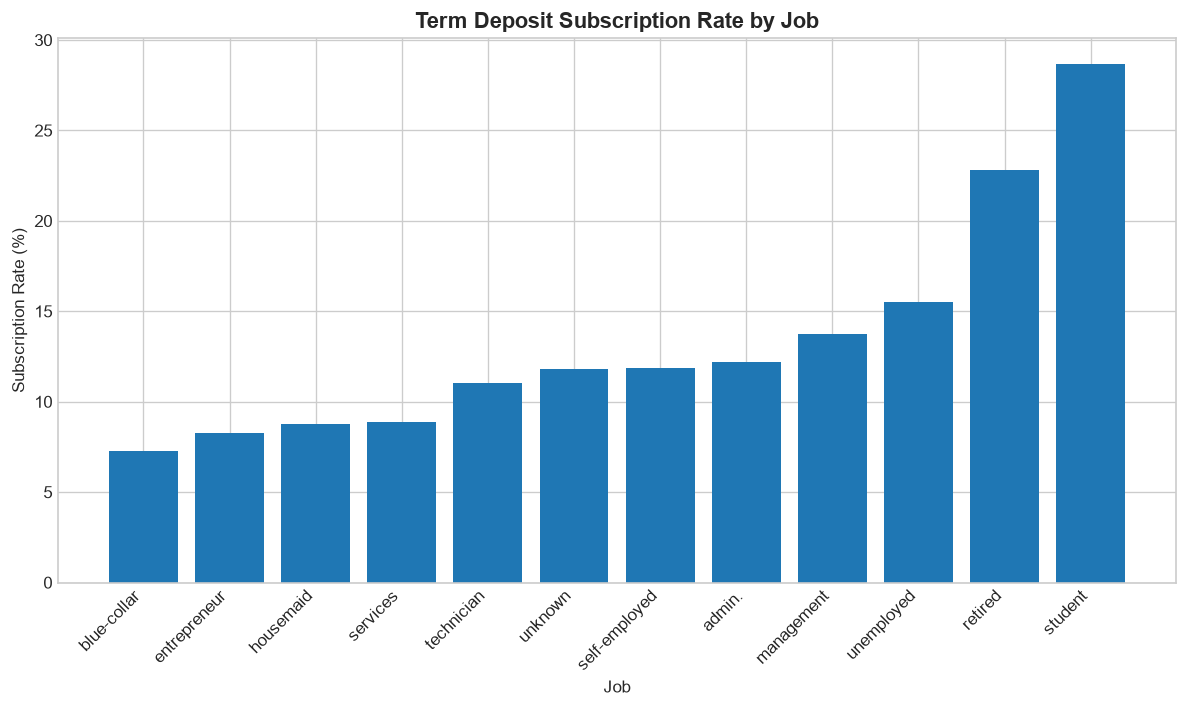

In [4]:
plt.figure(figsize=(10, 6))

plt.bar(
    job_substription.index, job_substription["yes"]
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Độ tuổi

Phân bố tuổi tập trung chủ yếu ở nhóm trưởng thành. Tỷ lệ `yes` theo nhóm tuổi cho thấy nhóm 60+ và 18–29 có tỷ lệ cao hơn các nhóm trung niên trong dữ liệu này. Nhóm 60+ có quy mô nhỏ hơn nên cần thận trọng khi tổng quát hóa.

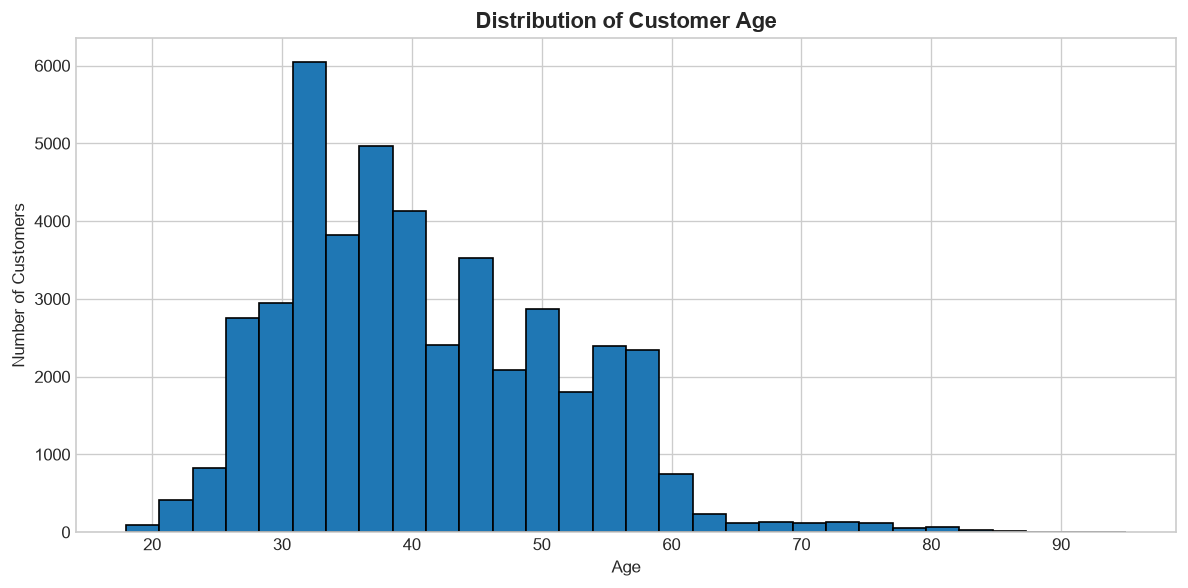

In [5]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["age"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [6]:
df.age.describe()

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

In [7]:
age_bins = [18, 30, 40, 50, 60, 100]

age_labels = [
    "18-29",
    "30-39",
    "40-49",
    "50-59",
    "60+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

df["age_group"].value_counts().sort_index()

age_group
18-29     5273
30-39    18089
40-49    11655
50-59     8410
60+       1784
Name: count, dtype: int64

In [8]:
age_subscription = pd.crosstab(
    df["age_group"],
    df["y"],
    normalize="index"
) * 100

print(age_subscription.round(2))

y             no    yes
age_group              
18-29      82.40  17.60
30-39      89.42  10.58
40-49      90.88   9.12
50-59      90.67   9.33
60+        66.37  33.63


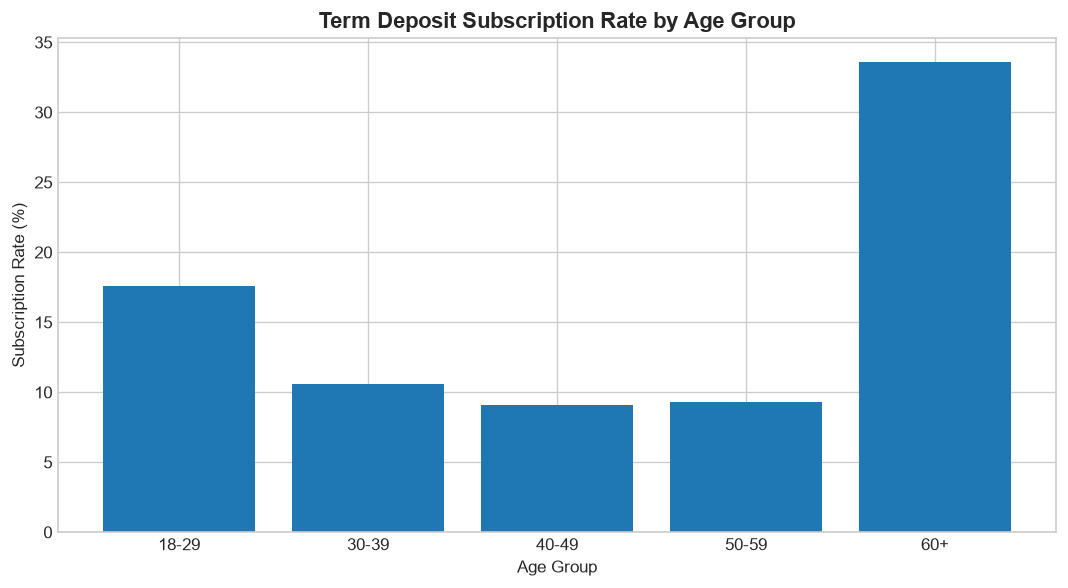

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(
    age_subscription.index.astype(str),
    age_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

## 3. Thông tin liên hệ và chiến dịch

### Thời lượng cuộc gọi (`duration`)

Khách đăng ký có thời lượng cuộc gọi trung vị và trung bình cao hơn rõ rệt. Tuy nhiên, `duration` chỉ được biết **sau khi cuộc gọi kết thúc**; dùng nó để dự đoán trước cuộc gọi sẽ gây rò rỉ thông tin mục tiêu. Vì vậy, đây là biến hữu ích để hiểu dữ liệu nhưng không được đưa vào feature set pre-campaign.

In [10]:
df["duration"].describe()

count    45211.000000
mean       258.163080
std        257.527812
min          0.000000
25%        103.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64

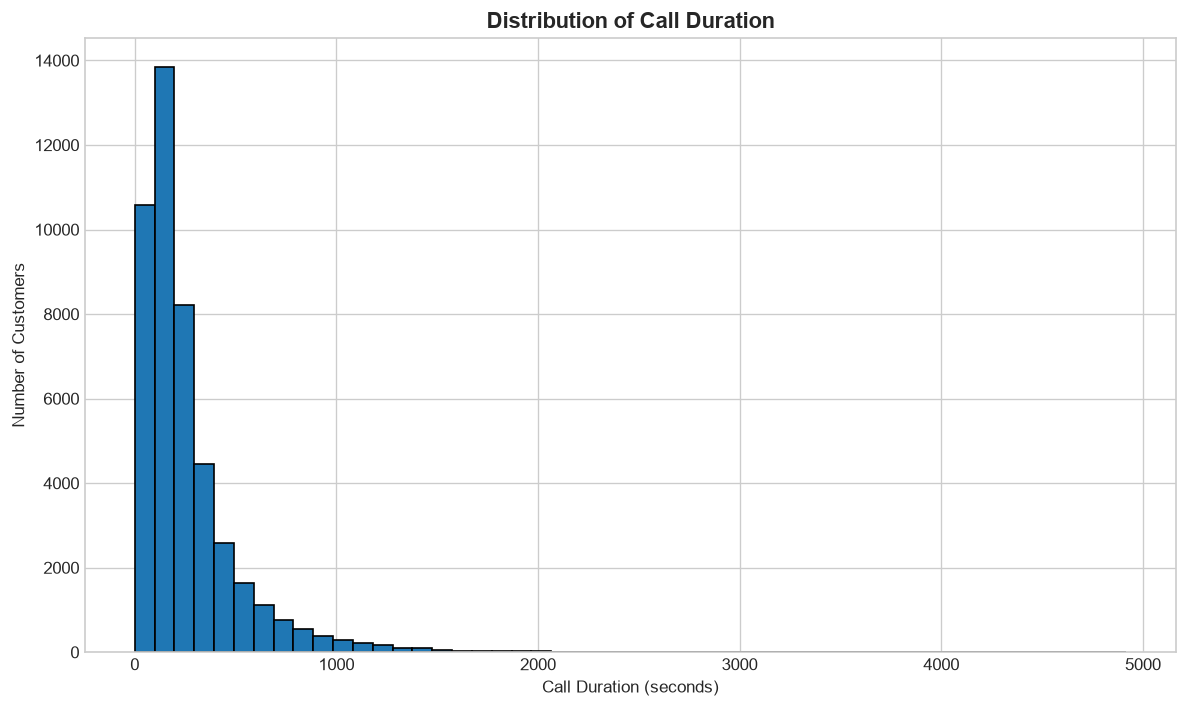

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["duration"],
    bins=50,
    edgecolor = "black"
)

plt.title("Distribution of Call Duration")
plt.xlabel("Call Duration (seconds)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [12]:
df.groupby("y")["duration"].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,221.182806,207.383237,0.0,95.0,164.0,279.0,4918.0
yes,5289.0,537.294574,392.525262,8.0,244.0,426.0,725.0,3881.0


### Kết quả chiến dịch trước (`poutcome`)

Nhóm có kết quả chiến dịch trước là `success` có tỷ lệ đăng ký cao hơn nhiều; tuy vậy nhóm này chỉ chiếm phần nhỏ dữ liệu. `poutcome` có thể được giữ nếu xác nhận đó là lịch sử có sẵn trước thời điểm dự đoán; giá trị `unknown` cần được hiểu là thiếu/không có thông tin lịch sử, không phải một kết quả thực tế.

In [13]:
poutcome_subscription = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

poutcome_subscription = poutcome_subscription.sort_values(
    by="yes",
    ascending=False
)

print(poutcome_subscription.round(2))

y            no    yes
poutcome              
success   35.27  64.73
other     83.32  16.68
failure   87.39  12.61
unknown   90.84   9.16


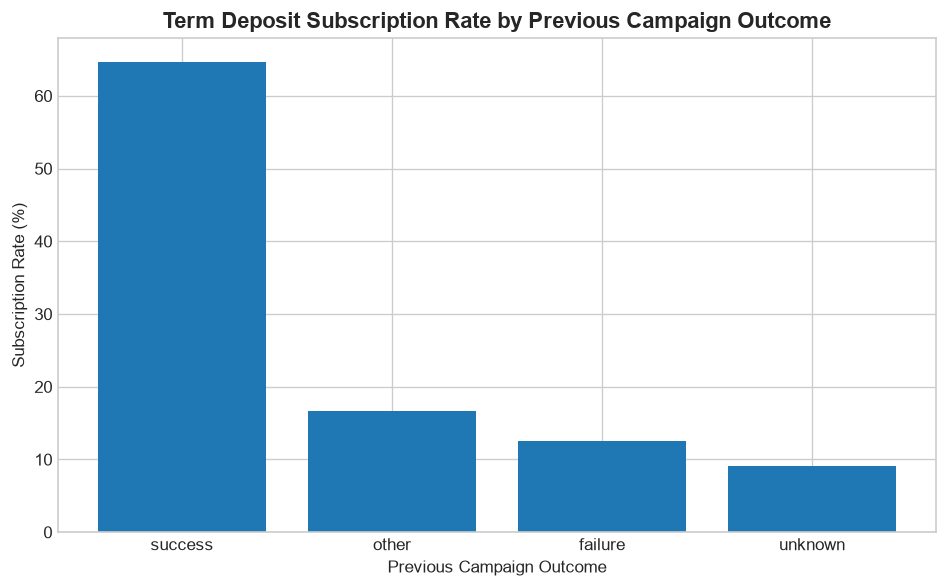

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    poutcome_subscription.index,
    poutcome_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

In [15]:
poutcome_counts = df["poutcome"].value_counts()

poutcome_summary = pd.DataFrame({
    "count": poutcome_counts,
    "percentage": (
        poutcome_counts / len(df) * 100
    ).round(2),
    "subscription_rate": (
        df.groupby("poutcome", observed=False)["y"]
        .apply(lambda values: (values == "yes").mean() * 100)
        .round(2)
    ),
})

print(poutcome_summary)

          count  percentage  subscription_rate
poutcome                                      
failure    4901       10.84              12.61
other      1840        4.07              16.68
success    1511        3.34              64.73
unknown   36959       81.75               9.16


### Tình trạng gia đình, học vấn và khoản vay

Các tỷ lệ theo `marital`, `education`, `housing`, `loan` và `default` cho thấy một số khác biệt giữa nhóm. Ví dụ, nhóm không có housing loan/personal loan có tỷ lệ đăng ký cao hơn trong mẫu. Đây là các đặc trưng nền có thể dùng làm ứng viên; cần giữ lại bằng đánh giá validation thay vì loại chỉ vì tương quan đơn biến yếu.

`default=yes` rất hiếm, nên tỷ lệ của nhóm này có thể dao động và cần đọc cùng support.

y            no    yes
marital               
single    85.05  14.95
divorced  88.05  11.95
married   89.88  10.12


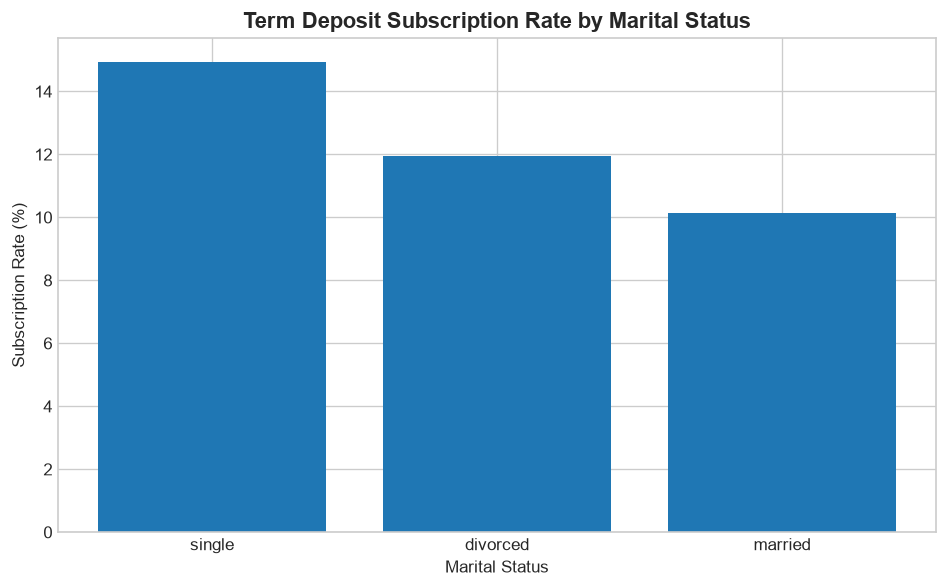

In [16]:
df["marital"].value_counts()

marital_subscription = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

marital_subscription = marital_subscription.sort_values(
    by="yes",
    ascending=False
)

print(marital_subscription.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    marital_subscription.index,
    marital_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

y             no    yes
education              
tertiary   84.99  15.01
unknown    86.43  13.57
secondary  89.44  10.56
primary    91.37   8.63


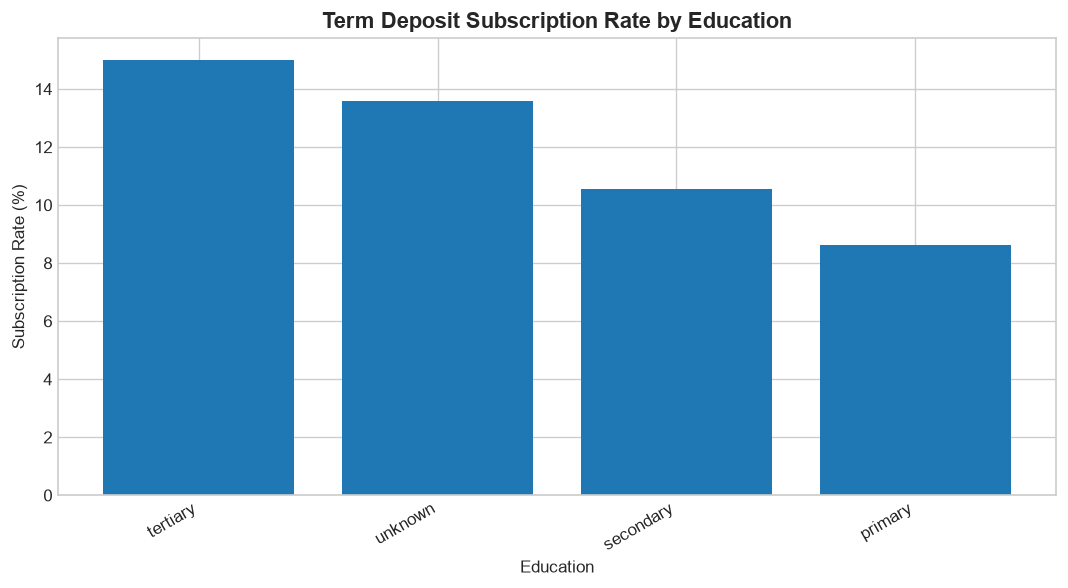

In [17]:
df["education"].value_counts()

education_subscription = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

education_subscription = education_subscription.sort_values(
    by="yes",
    ascending=False
)

print(education_subscription.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    education_subscription.index,
    education_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Subscription Rate (%)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [18]:
df["housing"].value_counts()

housing_subscription = pd.crosstab(
    df["housing"],
    df["y"],
    normalize="index"
) * 100

print(housing_subscription.round(2))

y          no   yes
housing            
no       83.3  16.7
yes      92.3   7.7


In [19]:
df["loan"].value_counts()

loan_subscription = pd.crosstab(
    df["loan"],
    df["y"],
    normalize="index"
) * 100

print(loan_subscription.round(2))

y        no    yes
loan              
no    87.34  12.66
yes   93.32   6.68


In [20]:
df["default"].value_counts()

default_subscription = pd.crosstab(
    df["default"],
    df["y"],
    normalize="index"
) * 100

print(default_subscription.round(2))

y           no    yes
default              
no       88.20  11.80
yes      93.62   6.38


In [21]:
df["default"].value_counts()

default
no     44396
yes      815
Name: count, dtype: int64

## 4. Số dư và lịch sử liên hệ

### Số dư (`balance`)

`balance` có phân phối lệch phải và ngoại lệ lớn; trung vị thường đại diện tốt hơn trung bình khi mô tả. Nhóm `yes` có trung vị số dư cao hơn nhóm `no`, nhưng hai phân phối chồng lấp đáng kể. Giữ làm ứng viên và để preprocessing/model xử lý; không xóa ngoại lệ tự động khi chưa có căn cứ nghiệp vụ.

In [22]:
df["balance"].describe()

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

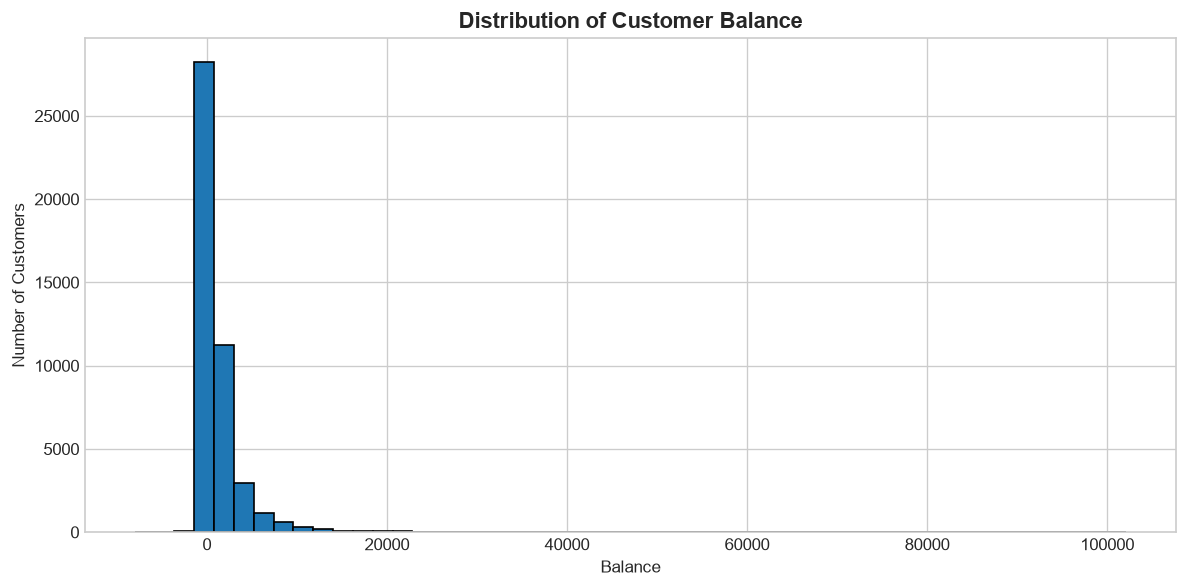

In [23]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["balance"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Customer Balance")
plt.xlabel("Balance")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

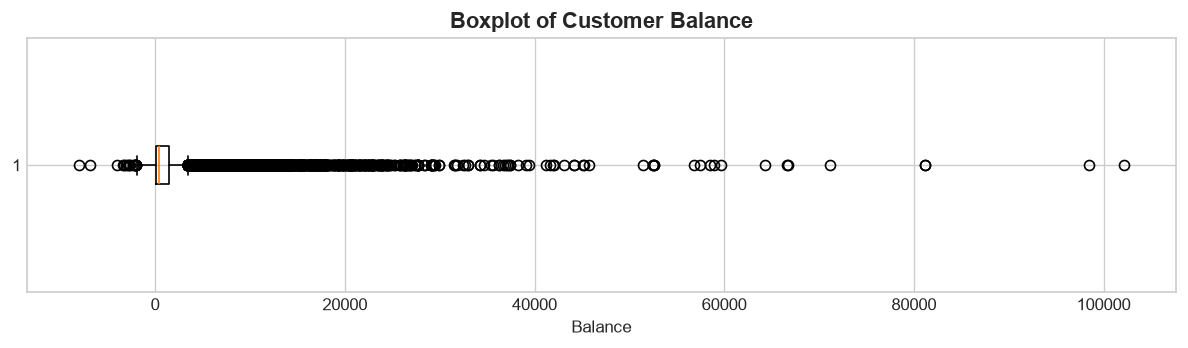

In [24]:
plt.figure(figsize=(10, 3))

plt.boxplot(
    df["balance"],
    orientation="horizontal"
)

plt.title("Boxplot of Customer Balance")
plt.xlabel("Balance")

plt.tight_layout()
plt.show()

In [25]:
balance_by_target = df.groupby("y")["balance"].describe()

display(balance_by_target)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,1303.714969,2974.195473,-8019.0,58.0,417.0,1345.0,102127.0
yes,5289.0,1804.267915,3501.104777,-3058.0,210.0,733.0,2159.0,81204.0


### Số lần liên hệ trong chiến dịch hiện tại (`campaign`)

Biến này đếm số lần liên hệ trong chiến dịch hiện tại, bao gồm cả các lần xảy ra sau lần dự đoán ban đầu. Dù có thể liên hệ với kết quả, nó **không sẵn có tại thời điểm pre-campaign** và còn có thể phản ánh quyết định tiếp tục liên hệ sau các lần trước. Vì vậy loại khỏi feature set của kịch bản pre-campaign.

In [26]:
df["campaign"].describe()

count    45211.000000
mean         2.763841
std          3.098021
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         63.000000
Name: campaign, dtype: float64

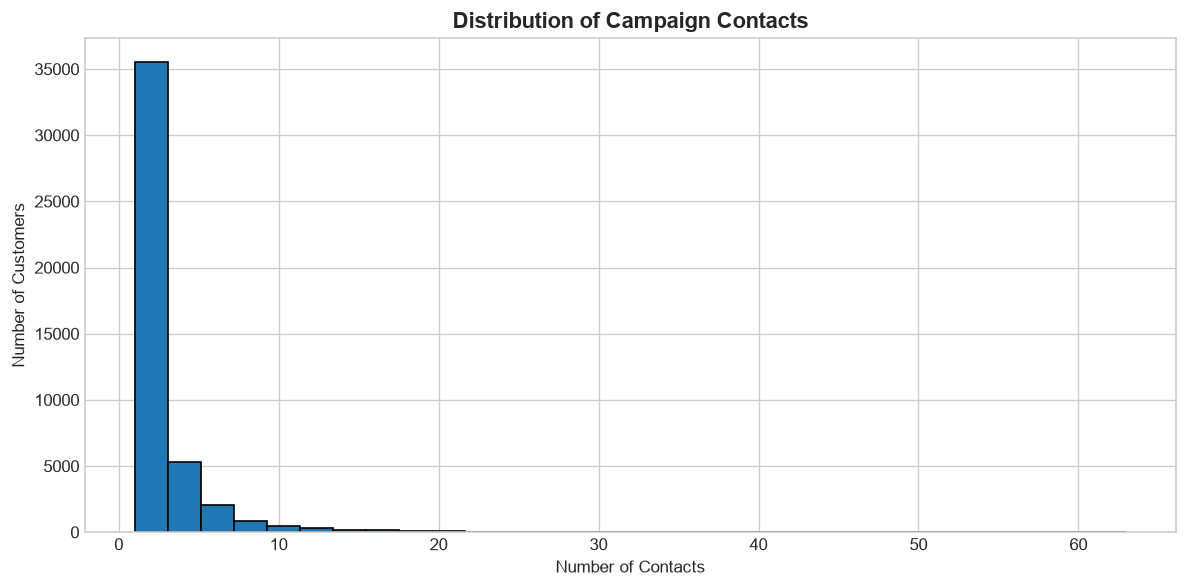

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["campaign"], bins=30, edgecolor="black")
plt.title("Distribution of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

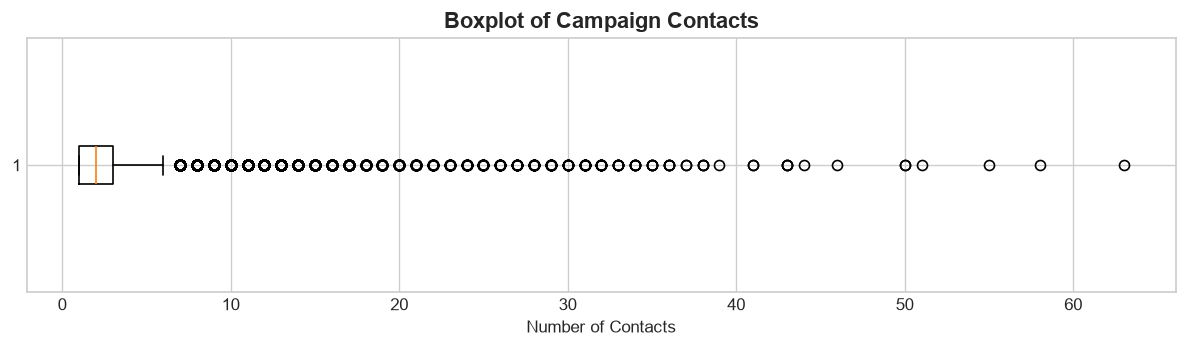

In [28]:
plt.figure(figsize=(10, 3))
plt.boxplot(df["campaign"], orientation="horizontal")
plt.title("Boxplot of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.tight_layout()
plt.show()

In [29]:
campaign_by_target = (
    df.groupby("y")["campaign"]
    .describe()
)

display(campaign_by_target)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,2.846350,3.212767,1.0,1.0,2.0,3.0,63.0
yes,5289.0,2.141047,1.921826,1.0,1.0,2.0,3.0,32.0


### Lịch sử liên hệ trước đó (`previous`, `pdays`)

`previous` và `pdays` mô tả lịch sử trước chiến dịch hiện tại; giá trị đặc biệt (`previous = 0`, `pdays = -1`) cần được diễn giải đúng là không có lần liên hệ trước/không có ngày liên hệ trước. Các biến này được giữ làm ứng viên **chỉ khi** hệ thống triển khai thực sự có dữ liệu lịch sử đó trước prediction point. Không chuyển giá trị sentinel thành missing một cách máy móc.

In [30]:
df["previous"].describe()

count    45211.000000
mean         0.580323
std          2.303441
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: previous, dtype: float64

In [31]:
previous_counts = df["previous"].value_counts()

print("Số khách hàng previous = 0:", previous_counts.get(0, 0))
print(
    "Tỷ lệ previous = 0:",
    f"{(df['previous'].eq(0).mean() * 100):.2f}%"
)

print("\nCác giá trị previous xuất hiện nhiều nhất:")
display(previous_counts.head(10))

Số khách hàng previous = 0: 36954
Tỷ lệ previous = 0: 81.74%

Các giá trị previous xuất hiện nhiều nhất:


previous
0    36954
1     2772
2     2106
3     1142
4      714
5      459
6      277
7      205
8      129
9       92
Name: count, dtype: int64

In [32]:
previous_by_target = (
    df.groupby("y")["previous"]
    .describe()
)

display(previous_by_target)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,0.502154,2.256771,0.0,0.0,0.0,0.0,275.0
yes,5289.0,1.170354,2.553272,0.0,0.0,0.0,1.0,58.0


In [33]:
previous_group = pd.Series(
    "No previous contact",
    index=df.index
)

previous_group[df["previous"] > 0] = "Previous contact"

previous_conversion = pd.crosstab(
    previous_group,
    df["y"],
    normalize="index"
) * 100

display(previous_conversion.round(2))

y,no,yes
row_0,,
No previous contact,90.84,9.16
Previous contact,76.93,23.07


In [34]:
df["pdays"].describe()

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64

In [35]:
pdays_counts = df["pdays"].value_counts()

print("Số khách hàng pdays = -1:", pdays_counts.get(-1, 0))

print(
    "Tỷ lệ pdays = -1:",
    f"{(df['pdays'].eq(-1).mean() * 100):.2f}%"
)

print(
    "Số khách hàng đã được liên hệ trước đó:",
    (df["pdays"] != -1).sum()
)

Số khách hàng pdays = -1: 36954
Tỷ lệ pdays = -1: 81.74%
Số khách hàng đã được liên hệ trước đó: 8257


In [36]:
pdays_group = pd.Series(
    "No previous contact",
    index=df.index
)

pdays_group[df["pdays"] != -1] = "Previous contact"

pdays_conversion = pd.crosstab(
    pdays_group,
    df["y"],
    normalize="index"
) * 100

display(pdays_conversion.round(2))

y,no,yes
row_0,,
No previous contact,90.84,9.16
Previous contact,76.93,23.07


In [37]:
pdays_contacted = df.loc[df["pdays"] != -1, "pdays"]

display(pdays_contacted.describe())

count    8257.000000
mean      224.577692
std       115.344035
min         1.000000
25%       133.000000
50%       194.000000
75%       327.000000
max       871.000000
Name: pdays, dtype: float64

## 5. Thời điểm và kênh liên hệ

`day`, `month` và `contact` có thể liên quan đến tỷ lệ đăng ký theo quan sát. Tuy nhiên, chúng mô tả lần liên hệ hiện tại; trong kịch bản dự đoán trước chiến dịch, ngày/kênh có thể chưa được quyết định hoặc chưa biết. Không mặc định đưa vào mô hình: chỉ giữ nếu nghiệp vụ xác nhận chúng đã có tại prediction point. Tỷ lệ theo thời gian cũng có thể chịu ảnh hưởng bởi mùa vụ và cách phân bổ chiến dịch.

In [38]:
df["day"].describe()

count    45211.000000
mean        15.806419
std          8.322476
min          1.000000
25%          8.000000
50%         16.000000
75%         21.000000
max         31.000000
Name: day, dtype: float64

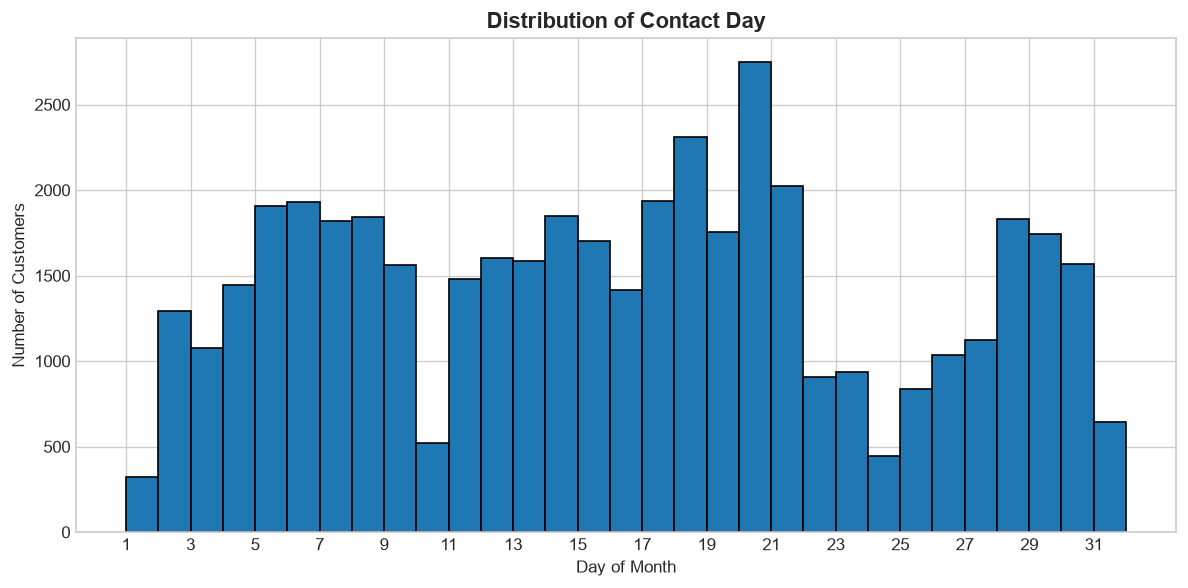

In [39]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["day"],
    bins=range(1, 33),
    edgecolor="black"
)

plt.title("Distribution of Contact Day")
plt.xlabel("Day of Month")
plt.ylabel("Number of Customers")
plt.xticks(range(1, 32, 2))
plt.tight_layout()
plt.show()

In [40]:
daily_conversion = (
    df.groupby("day")["y"]
    .apply(lambda s: (s == "yes").mean() * 100)
)

display(daily_conversion.round(2))

day
1     27.95
2     14.08
3     16.50
4     15.92
5     11.26
6      9.37
7      8.64
8     10.91
9     11.47
10    23.09
11    12.24
12    15.22
13    15.21
14    11.36
15    13.98
16    13.57
17     9.08
18     9.88
19     6.94
20     6.98
21     9.92
22    17.02
23    13.42
24    13.87
25    15.83
26    11.21
27    13.38
28     7.81
29     7.39
30    17.31
31     7.15
Name: y, dtype: float64

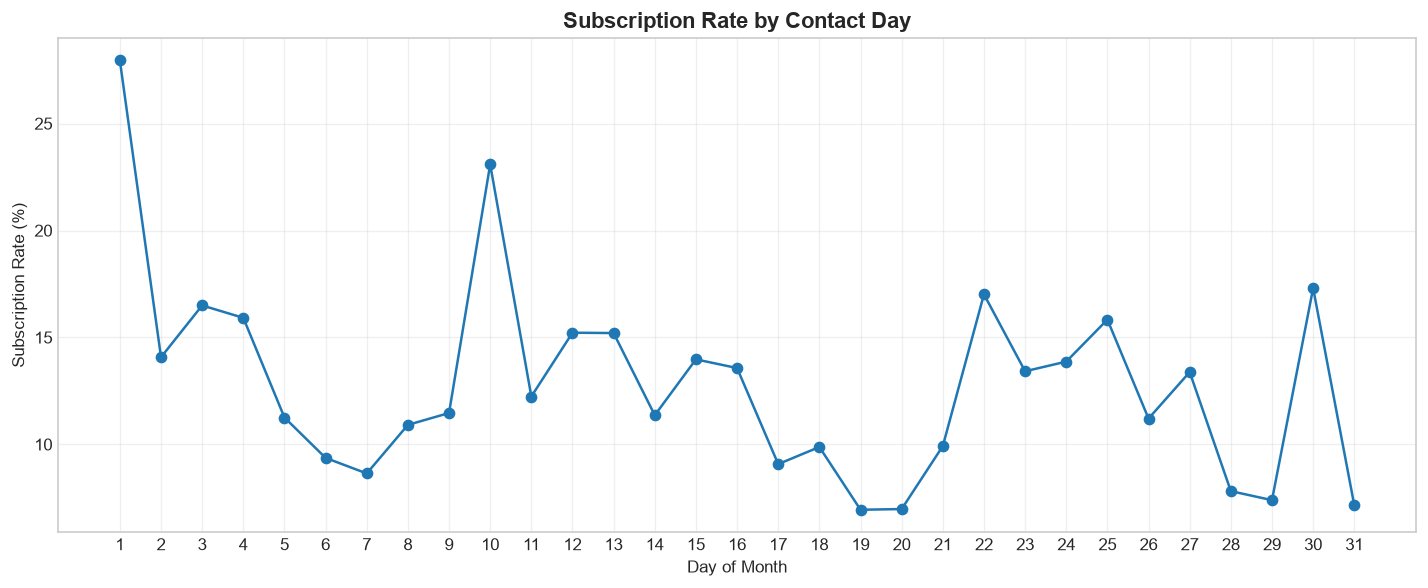

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_conversion.index,
    daily_conversion.values,
    marker="o"
)

plt.title("Subscription Rate by Contact Day")
plt.xlabel("Day of Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(range(1, 32))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
df["month"].value_counts()

month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64

In [43]:
monthly_conversion = (
    df.groupby("month")["y"]
    .apply(lambda s: (s == "yes").mean() * 100)
)

display(monthly_conversion.round(2))

month
apr    19.68
aug    11.01
dec    46.73
feb    16.65
jan    10.12
jul     9.09
jun    10.22
mar    51.99
may     6.72
nov    10.15
oct    43.77
sep    46.46
Name: y, dtype: float64

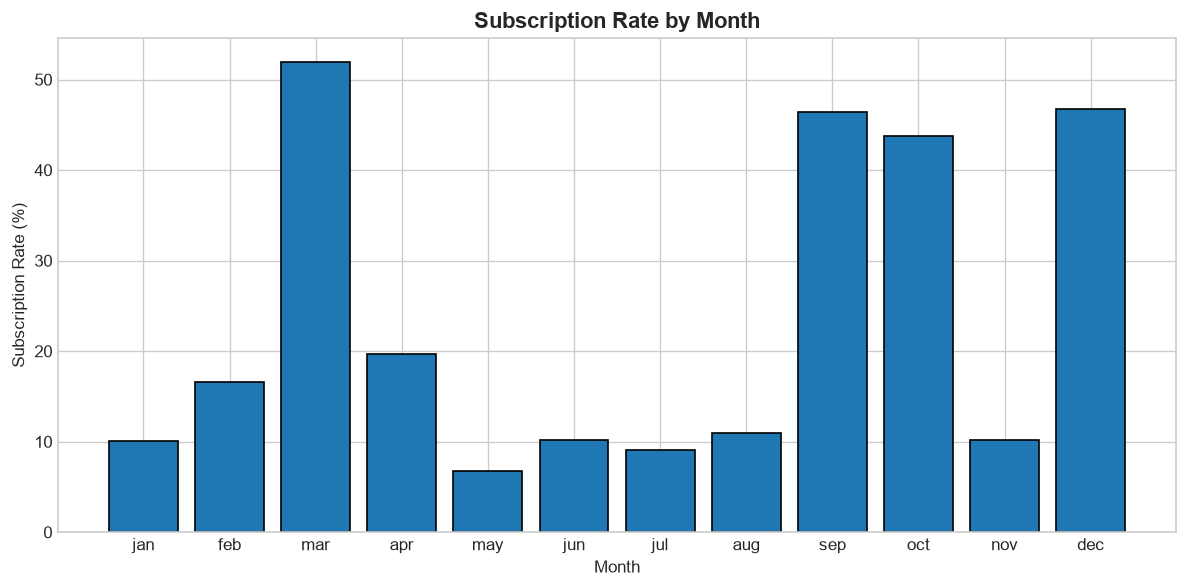

In [44]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

monthly_conversion_ordered = monthly_conversion.reindex(month_order)

plt.figure(figsize=(10, 5))
plt.bar(
    monthly_conversion_ordered.index,
    monthly_conversion_ordered.values,
    edgecolor="black"
)

plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

In [45]:
df["contact"].value_counts()

contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

In [46]:
contact_conversion = pd.crosstab(
    df["contact"],
    df["y"],
    normalize="index"
) * 100

display(contact_conversion.round(2))

y,no,yes
contact,,
cellular,85.08,14.92
telephone,86.58,13.42
unknown,95.93,4.07


## 6. Kết luận EDA và quyết định feature

### Ứng viên giữ lại cho mô hình pre-campaign

Các đặc trưng nền có thể biết trước khi bắt đầu chiến dịch: `age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan`; cùng lịch sử `pdays`, `previous`, `poutcome` **nếu** xác minh được lịch sử đã tồn tại tại thời điểm dự đoán. Kết quả đơn biến không phải tiêu chí duy nhất: quyết định cuối cùng cần dựa trên validation và kiểm tra tính sẵn có/ổn định của dữ liệu.

### Loại khỏi feature set pre-campaign

- **`duration`**: chỉ biết sau cuộc gọi, rò rỉ thông tin hậu nghiệm.
- **`campaign`**: phản ánh số lần liên hệ trong chiến dịch đang diễn ra; không biết đầy đủ trước chiến dịch và có thể mang thông tin từ quá trình can thiệp.
- **`y`**: nhãn mục tiêu, tuyệt đối không dùng làm đầu vào.
- **`contact`, `day`, `month`**: tạm thời chưa khẳng định giữ; cần chốt hợp đồng nghiệp vụ vì chúng mô tả lần liên hệ hiện tại.

### Lưu ý phương pháp

Các bảng EDA đang dùng toàn bộ dữ liệu chỉ để mô tả, không phải để chọn threshold/model hay báo cáo ước lượng holdout. Khi huấn luyện, preprocessing phải fit trên train; lựa chọn feature và cấu hình chỉ dựa trên train/validation. Các quan sát ở đây là liên hệ thống kê, không phải kết luận nhân quả.